## Proposed Dual-Graph AC-SMFAE
Dataset: Yale Face Dataset

### Data Ingestion, Preprocessing and Validation


In [2]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load Yale dataset
file_path = "../data/preprocessed/Yale.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"Dataset not found: {file_path}\n"
        f"Current working directory: {os.getcwd()}"
    )

df = pd.read_csv(file_path)

# 2. Separate features and ground-truth labels
X_raw = df.iloc[:, :-1].to_numpy(dtype=np.float64)
y = df.iloc[:, -1].to_numpy()

# 3. Validate input data
if pd.isna(y).any():
    raise ValueError("Missing values found in the label column.")

if not np.isfinite(X_raw).all():
    raise ValueError(
        "Features contain missing or infinite values. "
        "Resolve these before standardization."
    )

# 4. Z-score standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 5. Transpose to paper notation: pixels x samples
X = X_scaled.T

# 6. Display dataset summary
print("CELL 1: YALE DATASET — DATA INGESTION & SETUP")
print("Proposed Dual-Graph AC-SMFAE")

print(f"Dataset path              : {os.path.abspath(file_path)}")
print(f"Original DataFrame shape  : {df.shape}")
print(f"Raw feature matrix shape  : {X_raw.shape}")
print(f"Standardized matrix shape : {X.shape} (pixels x samples)")
print(f"Labels vector shape       : {y.shape}")
print(f"Number of samples         : {X.shape[1]}")
print(f"Number of features        : {X.shape[0]}")
print(f"Number of classes         : {len(np.unique(y))}")
print(f"Class labels              : {np.unique(y)}")
print(f"Missing values in X       : {np.isnan(X).sum()}")
print(f"Non-finite values in X    : {(~np.isfinite(X)).sum()}")


# 7. Validate expected dimensions and data quality
assert X.shape == (1024, 165), (
    f"Expected X shape (1024, 165), but got {X.shape}"
)
assert len(np.unique(y)) == 15, (
    f"Expected 15 classes, but found {len(np.unique(y))}"
)
assert np.isfinite(X).all(), "X contains non-finite values."

print("Dataset validation passed successfully.")

CELL 1: YALE DATASET — DATA INGESTION & SETUP
Proposed Dual-Graph AC-SMFAE
Dataset path              : d:\Projects\SMFS-AutoEncoder\data\preprocessed\Yale.csv
Original DataFrame shape  : (165, 1025)
Raw feature matrix shape  : (165, 1024)
Standardized matrix shape : (1024, 165) (pixels x samples)
Labels vector shape       : (165,)
Number of samples         : 165
Number of features        : 1024
Number of classes         : 15
Class labels              : [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
Missing values in X       : 0
Non-finite values in X    : 0
Dataset validation passed successfully.


In Yale dataset there 1024 pixel features, 165 samples with 15 classes. Applied the z-score Standardization. The dataset is ready for further setups

### Combination A: Single-Graph AC-SMFAE
Dataset: Yale

In [4]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, pairwise_distances
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment

# 1. Sigmoid activation
def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-np.clip(u, -15.0, 15.0)))

# 2. Hungarian matching accuracy
def accuracy_score_hungarian(y_true, y_pred):
    _, y_true_enc = np.unique(y_true, return_inverse=True)
    _, y_pred_enc = np.unique(y_pred, return_inverse=True)

    n_true = len(np.unique(y_true_enc))
    n_pred = len(np.unique(y_pred_enc))
    w = np.zeros((n_pred, n_true), dtype=np.int64)

    for i in range(len(y_pred_enc)):
        w[y_pred_enc[i], y_true_enc[i]] += 1

    row_ind, col_ind = linear_sum_assignment(w.max() - w)
    return w[row_ind, col_ind].sum() / len(y_pred_enc)

# 3. Adaptive sample graph
def construct_adaptive_graph(Z_or_X, k=5):
    dist_matrix = pairwise_distances(Z_or_X.T, metric="euclidean")
    n_samples = Z_or_X.shape[1]
    S = np.zeros((n_samples, n_samples))
    sigma = np.mean(dist_matrix) + 1e-8

    for i in range(n_samples):
        for j in np.argsort(dist_matrix[i])[:k + 1]:
            if i != j:
                sim = np.exp(
                    -(dist_matrix[i, j] ** 2) / (2 * sigma ** 2)
                )
                S[i, j] = sim
                S[j, i] = sim

    D = np.diag(S.sum(axis=1))
    L_S = D - S
    return S, D, L_S

# 4. Single-graph AC-SMFAE training
def train_single_graph_ac_smfae_yale(
    X, k=5, m=200, alpha=1e-2, beta=1e-4,
    gamma=1e-3, omega=0.01, lam=1e-4,
    lr=5e-4, epochs=500, update_graph_every=20
):
    d, n = X.shape
    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S_S, D_S, L_S = construct_adaptive_graph(X, k=k)
    loss_history = []

    print("=== Combination A: Single-Graph AC-SMFAE ===")
    print(f"Pixels={d}, Samples={n}, Latent={m}")

    for epoch in range(1, epochs + 1):
        Z = sigmoid(W1 @ X)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S_S, D_S, L_S = construct_adaptive_graph(Z, k=k)

        recon_err = X - X_hat
        loss_recon = 0.5 / n * np.sum(recon_err ** 2)

        w1_col_norms = np.linalg.norm(W1, axis=0) + 1e-8
        loss_sparse = alpha * np.sum(w1_col_norms)
        loss_weight_decay = 0.5 * beta * np.sum(W2 ** 2)
        loss_sample = 0.5 / n * gamma * np.trace(Z @ L_S @ Z.T)

        output_diff = H.T @ H - L_S
        loss_output = 0.5 / n * omega * np.sum(output_diff ** 2)

        d_sig = Z * (1 - Z)
        h_prime_sum = np.sum(d_sig ** 2, axis=1)
        w1_sq_rows = np.sum(W1 ** 2, axis=1)
        loss_cae = lam * np.sum(h_prime_sum * w1_sq_rows)

        total_loss = (
            loss_recon + loss_sparse + loss_weight_decay
            + loss_sample + loss_output + loss_cae
        )
        loss_history.append(float(total_loss))

        grad_W2 = -(recon_err @ Z.T) / n + beta * W2
        dL_dZ = -(W2.T @ recon_err) / n + gamma * (Z @ L_S) / n
        grad_W1_base = (dL_dZ * d_sig) @ X.T
        grad_W1_sparse = alpha * W1 / w1_col_norms[None, :]

        A_mat = 2 * d_sig ** 2 * (1 - 2 * Z)
        grad_cae_1 = 2 * h_prime_sum[:, None] * W1
        grad_cae_2 = w1_sq_rows[:, None] * (A_mat @ X.T)
        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = np.clip(
            grad_W1_base + grad_W1_sparse + grad_W1_cae, -5, 5
        )
        grad_W2 = np.clip(grad_W2, -5, 5)

        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        num_H = H @ D_S
        den_H = H @ H.T @ H + H @ S_S + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"Epoch {epoch:3d}/{epochs} | "
                f"Total: {total_loss:.4f} | "
                f"Recon: {loss_recon:.4f}"
            )

    return W1, W2, H, loss_history

# 5. Train Combination A
W1_comb_a_yale, W2_comb_a_yale, H_comb_a_yale, loss_hist_comb_a_yale = (
    train_single_graph_ac_smfae_yale(X)
)

# 6. Evaluate selected pixels
r_subsets = [2, 10, 20, 50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20

pixel_scores_a = np.linalg.norm(W1_comb_a_yale, axis=0)
ranked_indices_a = np.argsort(pixel_scores_a)[::-1]
results_comb_a_yale = {}

print("\n=== Combination A Evaluation Results (Yale) ===")
print("Pixels | ACC mean ± std (%) | NMI mean ± std (%)")

for r in r_subsets:
    X_sel = StandardScaler().fit_transform(
        X[ranked_indices_a[:r], :].T
    )
    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes, n_init=10, random_state=rep
        ).fit_predict(X_sel)

        acc_list.append(100 * accuracy_score_hungarian(y, labels))
        nmi_list.append(
            100 * normalized_mutual_info_score(y, labels)
        )

    results_comb_a_yale[r] = {
        "ACC_mean": np.mean(acc_list),
        "ACC_std": np.std(acc_list),
        "NMI_mean": np.mean(nmi_list),
        "NMI_std": np.std(nmi_list)
    }

    res = results_comb_a_yale[r]
    print(
        f"{r:3d} | {res['ACC_mean']:.2f} ± {res['ACC_std']:.2f} | "
        f"{res['NMI_mean']:.2f} ± {res['NMI_std']:.2f}"
    )

print("\nCombination A results stored in results_comb_a_yale.")

=== Combination A: Single-Graph AC-SMFAE ===
Pixels=1024, Samples=165, Latent=200
Epoch   1/500 | Total: 14576.7814 | Recon: 832.7437
Epoch 100/500 | Total: 441.4537 | Recon: 434.7106
Epoch 200/500 | Total: 375.5396 | Recon: 368.8282
Epoch 300/500 | Total: 331.9423 | Recon: 325.2480
Epoch 400/500 | Total: 301.4005 | Recon: 294.7155
Epoch 500/500 | Total: 278.7215 | Recon: 272.0425

=== Combination A Evaluation Results (Yale) ===
Pixels | ACC mean ± std (%) | NMI mean ± std (%)
  2 | 25.06 ± 0.92 | 30.99 ± 1.27
 10 | 33.79 ± 2.45 | 40.96 ± 1.93
 20 | 32.21 ± 3.29 | 40.95 ± 2.45
 50 | 38.21 ± 3.18 | 45.46 ± 2.30
100 | 42.85 ± 3.26 | 50.03 ± 2.05
150 | 42.39 ± 3.19 | 50.61 ± 2.69
200 | 42.33 ± 2.98 | 50.29 ± 2.24
250 | 44.48 ± 2.77 | 52.65 ± 2.55
300 | 48.18 ± 2.50 | 55.63 ± 2.06

Combination A results stored in results_comb_a_yale.


### Combination C: Dual-Graph AC-SMFAE
Dataset: Yale

In [5]:

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, pairwise_distances
from sklearn.preprocessing import StandardScaler

def construct_feature_graph_yale(X, k=5):
    # Build a graph between features (pixels)
    dist_matrix = pairwise_distances(X, metric="euclidean")
    n_features = X.shape[0]

    S_F = np.zeros((n_features, n_features))
    sigma = np.mean(dist_matrix) + 1e-8

    for i in range(n_features):
        nearest = np.argsort(dist_matrix[i])[:k + 1]
        for j in nearest:
            if i != j:
                sim = np.exp(
                    -(dist_matrix[i, j] ** 2) / (2 * sigma ** 2)
                )
                S_F[i, j] = sim
                S_F[j, i] = sim

    D_F = np.diag(S_F.sum(axis=1))
    L_F = D_F - S_F
    return S_F, D_F, L_F


def train_dual_graph_ac_smfae_yale(
    X, k=5, m=200, alpha=1e-2, beta=1e-4,
    gamma=1e-3, omega=0.01, lam=1e-4, eta=0.01,
    lr=5e-4, epochs=500, update_graph_every=20
):
    d, n = X.shape

    np.random.seed(42)
    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S_S, D_S, L_S = construct_adaptive_graph(X, k=k)
    S_F, D_F, L_F = construct_feature_graph_yale(X, k=k)

    loss_history = []

    print("=== Combination C: Dual-Graph AC-SMFAE ===")
    print(f"Pixels={d}, Samples={n}, Latent={m}")

    for epoch in range(1, epochs + 1):
        Z = sigmoid(W1 @ X)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S_S, D_S, L_S = construct_adaptive_graph(Z, k=k)
            S_F, D_F, L_F = construct_feature_graph_yale(X, k=k)

        recon_err = X - X_hat

        loss_recon = 0.5 / n * np.sum(recon_err ** 2)
        w1_col_norms = np.linalg.norm(W1, axis=0) + 1e-8
        loss_sparse = alpha * np.sum(w1_col_norms)
        loss_weight_decay = 0.5 * beta * np.sum(W2 ** 2)
        loss_sample = 0.5 / n * gamma * np.trace(Z @ L_S @ Z.T)

        output_diff = H.T @ H - L_S
        loss_output = 0.5 / n * omega * np.sum(output_diff ** 2)

        feature_graph_loss = 0.5 * eta * np.trace(W1 @ L_F @ W1.T)

        d_sig = Z * (1 - Z)
        h_prime_sum = np.sum(d_sig ** 2, axis=1)
        w1_sq_rows = np.sum(W1 ** 2, axis=1)
        loss_cae = lam * np.sum(h_prime_sum * w1_sq_rows)

        total_loss = (
            loss_recon + loss_sparse + loss_weight_decay
            + loss_sample + loss_output
            + feature_graph_loss + loss_cae
        )
        loss_history.append(float(total_loss))

        # Parameter gradients
        grad_W2 = -(recon_err @ Z.T) / n + beta * W2

        dL_dZ = (
            -(W2.T @ recon_err) / n
            + gamma * (Z @ L_S) / n
        )

        grad_W1_base = (dL_dZ * d_sig) @ X.T
        grad_W1_sparse = alpha * W1 / w1_col_norms[None, :]

        # Feature-graph regularization gradient
        grad_W1_feature = eta * W1 @ L_F

        # Contractive autoencoder penalty gradient
        A_mat = 2 * d_sig ** 2 * (1 - 2 * Z)
        grad_cae_1 = 2 * h_prime_sum[:, None] * W1
        grad_cae_2 = w1_sq_rows[:, None] * (A_mat @ X.T)
        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = np.clip(
            grad_W1_base + grad_W1_sparse
            + grad_W1_feature + grad_W1_cae,
            -5, 5
        )
        grad_W2 = np.clip(grad_W2, -5, 5)

        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        num_H = H @ D_S
        den_H = H @ H.T @ H + H @ S_S + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"Epoch {epoch:3d}/{epochs} | "
                f"Total: {total_loss:.4f} | "
                f"Recon: {loss_recon:.4f} | "
                f"Feature graph: {feature_graph_loss:.4f}"
            )

    return W1, W2, H, loss_history


# Train Combination C
W1_comb_c_yale, W2_comb_c_yale, H_comb_c_yale, loss_hist_comb_c_yale = (
    train_dual_graph_ac_smfae_yale(X)
)

# Evaluate selected pixel subsets
r_subsets = [2, 10, 20, 50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20

pixel_scores_c = np.linalg.norm(W1_comb_c_yale, axis=0)
ranked_indices_c = np.argsort(pixel_scores_c)[::-1]

results_comb_c_yale = {}

print("\n=== Combination C Evaluation Results (Yale) ===")
print("Pixels | ACC mean ± std (%) | NMI mean ± std (%)")

for r in r_subsets:
    X_sel = StandardScaler().fit_transform(
        X[ranked_indices_c[:r], :].T
    )

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes,
            n_init=10,
            random_state=rep
        ).fit_predict(X_sel)

        acc_list.append(100 * accuracy_score_hungarian(y, labels))
        nmi_list.append(
            100 * normalized_mutual_info_score(y, labels)
        )

    results_comb_c_yale[r] = {
        "ACC_mean": np.mean(acc_list),
        "ACC_std": np.std(acc_list),
        "NMI_mean": np.mean(nmi_list),
        "NMI_std": np.std(nmi_list)
    }

    res = results_comb_c_yale[r]
    print(
        f"{r:3d} | "
        f"{res['ACC_mean']:.2f} ± {res['ACC_std']:.2f} | "
        f"{res['NMI_mean']:.2f} ± {res['NMI_std']:.2f}"
    )

print("\nCombination C results stored in results_comb_c_yale.")


=== Combination C: Dual-Graph AC-SMFAE ===
Pixels=1024, Samples=165, Latent=200
Epoch   1/500 | Total: 14588.0034 | Recon: 832.7437 | Feature graph: 11.2221
Epoch 100/500 | Total: 452.4984 | Recon: 434.6785 | Feature graph: 11.0958
Epoch 200/500 | Total: 386.4341 | Recon: 368.7820 | Feature graph: 10.9784
Epoch 300/500 | Total: 342.7016 | Recon: 325.1945 | Feature graph: 10.8688
Epoch 400/500 | Total: 312.0327 | Recon: 294.6575 | Feature graph: 10.7647
Epoch 500/500 | Total: 289.2326 | Recon: 271.9814 | Feature graph: 10.6647

=== Combination C Evaluation Results (Yale) ===
Pixels | ACC mean ± std (%) | NMI mean ± std (%)
  2 | 25.06 ± 0.92 | 30.99 ± 1.27
 10 | 33.79 ± 2.45 | 40.96 ± 1.93
 20 | 30.48 ± 2.33 | 39.53 ± 1.84
 50 | 39.30 ± 3.20 | 46.79 ± 2.31
100 | 39.73 ± 2.62 | 47.64 ± 1.59
150 | 42.42 ± 2.72 | 50.63 ± 2.46
200 | 43.82 ± 2.61 | 51.67 ± 1.95
250 | 44.00 ± 3.42 | 52.53 ± 2.22
300 | 46.79 ± 3.01 | 54.26 ± 2.77

Combination C results stored in results_comb_c_yale.


Why Didn't Combination C Show a Major Improvement on Yale?

- **Pixel-to-Pixel Correlation vs. Gene Pathways:**
  - In gene datasets such as Leukemia and Colon, genes form connected networks, so the feature graph (\(L_F\)) can improve performance.
  - However, Yale is a **face image dataset with 1,024 pixels**. Building a graph between pixels using simple cosine similarity, with a feature graph weight of \(\eta = 0.01\), may have caused some over-smoothing of important facial details, such as the eyes, nose, and mouth.

### Fine-Tuned Combination A

Combination A does not use the feature graph (\(L_F\)), so \(\eta = 0\). Fine-tuning Combination A with a latent dimension of \(m = 100\) and a sparsity weight of \(\alpha = 10^{-3}\) may improve performance on the Yale dataset.

In [11]:

# UPDATED COMBINATION A — YALE

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler

# 1. Updated Combination A training function
def train_updated_combination_a_yale(
    X, k=5, m=100, alpha=1e-3, beta=1e-4,
    gamma=1e-3, omega=0.01, lam=1e-4,
    lr=5e-4, epochs=500, update_graph_every=20
):
    d, n = X.shape
    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S_S, D_S, L_S = construct_adaptive_graph(X, k=k)
    loss_history = []

    print("=== Training Updated Combination A (Yale) ===")
    print(
        f"Pixels={d}, Samples={n}, Latent Dim={m}, "
        f"Alpha={alpha}, Gamma={gamma}, Lambda={lam}"
    )

    for epoch in range(1, epochs + 1):
        Z = sigmoid(W1 @ X)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S_S, D_S, L_S = construct_adaptive_graph(Z, k=k)

        recon_err = X - X_hat
        loss_recon = 0.5 / n * np.sum(recon_err ** 2)

        w1_col_norms = np.linalg.norm(W1, axis=0) + 1e-8
        loss_sparse = alpha * np.sum(w1_col_norms)
        loss_weight_decay = 0.5 * beta * np.sum(W2 ** 2)
        loss_sample = 0.5 / n * gamma * np.trace(Z @ L_S @ Z.T)

        output_diff = H.T @ H - L_S
        loss_output = 0.5 / n * omega * np.sum(output_diff ** 2)

        d_sig = Z * (1.0 - Z)
        h_prime_sum = np.sum(d_sig ** 2, axis=1)
        w1_sq_rows = np.sum(W1 ** 2, axis=1)
        loss_cae = lam * np.sum(h_prime_sum * w1_sq_rows)

        total_loss = (
            loss_recon + loss_sparse + loss_weight_decay
            + loss_sample + loss_output + loss_cae
        )
        loss_history.append(float(total_loss))

        grad_W2 = -(recon_err @ Z.T) / n + beta * W2

        dL_dZ = (
            -(W2.T @ recon_err) / n
            + gamma * (Z @ L_S) / n
        )
        grad_W1_base = (dL_dZ * d_sig) @ X.T
        grad_W1_sparse = alpha * W1 / w1_col_norms[None, :]

        A_mat = 2.0 * d_sig ** 2 * (1.0 - 2.0 * Z)
        grad_cae_1 = 2.0 * h_prime_sum[:, None] * W1
        grad_cae_2 = w1_sq_rows[:, None] * (A_mat @ X.T)
        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = np.clip(
            grad_W1_base + grad_W1_sparse + grad_W1_cae,
            -5.0, 5.0
        )
        grad_W2 = np.clip(grad_W2, -5.0, 5.0)

        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        num_H = H @ D_S
        den_H = H @ H.T @ H + H @ S_S + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"Epoch {epoch:3d}/{epochs} | "
                f"Total: {total_loss:.4f} | "
                f"Recon: {loss_recon:.4f}"
            )

    return W1, W2, H, loss_history


# 2. Train the updated model
W1_up_a, W2_up_a, H_up_a, loss_hist_up_a = (
    train_updated_combination_a_yale(
        X, k=5, m=100, alpha=1e-3, beta=1e-4,
        gamma=1e-3, omega=0.01, lam=1e-4,
        lr=5e-4, epochs=500, update_graph_every=20
    )
)

# 3. Evaluate selected pixel subsets
pixel_scores_up_a = np.linalg.norm(W1_up_a, axis=0)
ranked_indices_up_a = np.argsort(pixel_scores_up_a)[::-1]

r_subsets = [2, 10, 20, 50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20

results_up_a_yale = {}

print("\n=== Updated Combination A Evaluation Results (Yale) ===")
print("Pixels | ACC mean ± std (%) | NMI mean ± std (%)")

for r in r_subsets:
    X_sel = StandardScaler().fit_transform(
        X[ranked_indices_up_a[:r], :].T
    )

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes,
            n_init=10,
            random_state=rep
        ).fit_predict(X_sel)

        acc_list.append(100 * accuracy_score_hungarian(y, labels))
        nmi_list.append(
            100 * normalized_mutual_info_score(y, labels)
        )

    results_up_a_yale[r] = {
        "ACC_mean": float(np.mean(acc_list)),
        "ACC_std": float(np.std(acc_list)),
        "NMI_mean": float(np.mean(nmi_list)),
        "NMI_std": float(np.std(nmi_list))
    }

    res = results_up_a_yale[r]
    print(
        f"{r:3d} | "
        f"{res['ACC_mean']:.2f} ± {res['ACC_std']:.2f} | "
        f"{res['NMI_mean']:.2f} ± {res['NMI_std']:.2f}"
    )

print("\nUpdated Combination A evaluation completed.")


=== Training Updated Combination A (Yale) ===
Pixels=1024, Samples=165, Latent Dim=100, Alpha=0.001, Gamma=0.001, Lambda=0.0001
Epoch   1/500 | Total: 4170.6584 | Recon: 839.3566
Epoch 100/500 | Total: 495.7353 | Recon: 494.9867
Epoch 200/500 | Total: 437.6412 | Recon: 436.9010
Epoch 300/500 | Total: 402.5949 | Recon: 401.8597
Epoch 400/500 | Total: 374.1006 | Recon: 373.3693
Epoch 500/500 | Total: 350.6359 | Recon: 349.9080

=== Updated Combination A Evaluation Results (Yale) ===
Pixels | ACC mean ± std (%) | NMI mean ± std (%)
  2 | 29.48 ± 1.23 | 34.63 ± 1.27
 10 | 33.82 ± 1.96 | 39.93 ± 1.08
 20 | 36.55 ± 2.23 | 42.79 ± 1.51
 50 | 40.73 ± 2.72 | 47.81 ± 2.09
100 | 39.67 ± 2.47 | 47.75 ± 2.08
150 | 44.12 ± 3.51 | 52.39 ± 2.83
200 | 43.33 ± 2.91 | 52.01 ± 2.49
250 | 45.73 ± 4.36 | 53.86 ± 2.63
300 | 47.12 ± 3.67 | 54.65 ± 2.94

Updated Combination A evaluation completed.


### Fine-Tuned Combination C 

**Yale Dataset Fine-Tuning Strategy**

1. **m = 100 (Latent Dimension):** Reduces the latent dimension from 200 to 100 to help prevent overfitting on the Yale dataset, which contains only 165 samples.
2. **eta = 0.005 (Feature Graph Weight):** Slightly reduces the feature graph penalty to help prevent over-smoothing of fine pixel details and facial features.
3. **alpha = 1e-3 (Column Sparsity Weight):** Adjusts the \(L_{2,1}\) sparsity to improve the ranking of important facial features.

In [10]:

# FINE-TUNED COMBINATION C — YALE

import os
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, pairwise_distances
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment

# 1. Activation function
def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-np.clip(u, -15.0, 15.0)))


# 2. Hungarian matching accuracy
def accuracy_score_hungarian(y_true, y_pred):
    _, true_encoded = np.unique(y_true, return_inverse=True)
    _, pred_encoded = np.unique(y_pred, return_inverse=True)

    n_true = len(np.unique(true_encoded))
    n_pred = len(np.unique(pred_encoded))
    contingency = np.zeros((n_pred, n_true), dtype=np.int64)

    for i in range(len(pred_encoded)):
        contingency[pred_encoded[i], true_encoded[i]] += 1

    row_ind, col_ind = linear_sum_assignment(
        contingency.max() - contingency
    )
    return contingency[row_ind, col_ind].sum() / len(pred_encoded)


# 3. Adaptive sample graph
def construct_adaptive_graph(Z_or_X, k=5):
    distances = pairwise_distances(Z_or_X.T, metric="euclidean")
    n_samples = Z_or_X.shape[1]
    S = np.zeros((n_samples, n_samples))
    sigma = np.mean(distances) + 1e-8

    for i in range(n_samples):
        for j in np.argsort(distances[i])[:k + 1]:
            if i != j:
                similarity = np.exp(
                    -(distances[i, j] ** 2) / (2 * sigma ** 2)
                )
                S[i, j] = similarity
                S[j, i] = similarity

    D = np.diag(S.sum(axis=1))
    return S, D, D - S


# 4. Feature graph using cosine distance
def construct_feature_graph_yale(X, k=5):
    distances = pairwise_distances(X, metric="cosine")
    n_features = X.shape[0]
    S_F = np.zeros((n_features, n_features), dtype=np.float32)
    sigma = np.mean(distances) + 1e-8

    for i in range(n_features):
        for j in np.argsort(distances[i])[:k + 1]:
            if i != j:
                similarity = np.exp(
                    -(distances[i, j] ** 2) / (2 * sigma ** 2)
                )
                S_F[i, j] = similarity
                S_F[j, i] = similarity

    D_F = np.diag(S_F.sum(axis=1))
    return D_F - S_F


# 5. Fine-tuned dual-graph model
def train_finetuned_dual_graph_ac_smfae_yale(
    X, k=5, m=100, alpha=1e-3, beta=1e-4,
    gamma=1e-3, omega=0.01, lam=1e-4, eta=0.005,
    lr=5e-4, epochs=500, update_graph_every=20
):
    d, n = X.shape
    np.random.seed(42)

    W1 = np.random.randn(m, d) * np.sqrt(2.0 / d)
    W2 = np.random.randn(d, m) * np.sqrt(2.0 / m)
    H = np.abs(np.random.randn(m, n)) + 1e-5

    S_S, D_S, L_S = construct_adaptive_graph(X, k=k)
    L_F = construct_feature_graph_yale(X, k=k)
    loss_history = []

    print("=== Fine-Tuned Combination C: Yale ===")
    print(
        f"Pixels={d}, Samples={n}, Latent={m}, "
        f"Alpha={alpha}, Eta={eta}, Lambda={lam}"
    )

    for epoch in range(1, epochs + 1):
        Z = sigmoid(W1 @ X)
        X_hat = W2 @ Z

        if epoch > 1 and epoch % update_graph_every == 0:
            S_S, D_S, L_S = construct_adaptive_graph(Z, k=k)

        recon_err = X - X_hat
        loss_recon = 0.5 / n * np.sum(recon_err ** 2)

        w1_col_norms = np.linalg.norm(W1, axis=0) + 1e-8
        loss_sparse = alpha * np.sum(w1_col_norms)
        loss_weight_decay = 0.5 * beta * np.sum(W2 ** 2)
        loss_sample = 0.5 / n * gamma * np.trace(Z @ L_S @ Z.T)
        loss_feature = 0.5 / n * eta * np.trace(W1 @ L_F @ W1.T)

        output_diff = H.T @ H - L_S
        loss_output = 0.5 / n * omega * np.sum(output_diff ** 2)

        d_sig = Z * (1.0 - Z)
        h_prime_sum = np.sum(d_sig ** 2, axis=1)
        w1_sq_rows = np.sum(W1 ** 2, axis=1)
        loss_cae = lam * np.sum(h_prime_sum * w1_sq_rows)

        total_loss = (
            loss_recon + loss_sparse + loss_weight_decay
            + loss_sample + loss_feature + loss_output + loss_cae
        )
        loss_history.append(float(total_loss))

        grad_W2 = -(recon_err @ Z.T) / n + beta * W2

        dL_dZ = (
            -(W2.T @ recon_err) / n
            + gamma * (Z @ L_S) / n
        )
        grad_W1_base = (dL_dZ * d_sig) @ X.T
        grad_W1_sparse = alpha * W1 / w1_col_norms[None, :]
        grad_W1_feature = (eta / n) * (W1 @ L_F)

        A_mat = 2.0 * d_sig ** 2 * (1.0 - 2.0 * Z)
        grad_cae_1 = 2.0 * h_prime_sum[:, None] * W1
        grad_cae_2 = w1_sq_rows[:, None] * (A_mat @ X.T)
        grad_W1_cae = lam * (grad_cae_1 + grad_cae_2)

        grad_W1 = np.clip(
            grad_W1_base + grad_W1_sparse
            + grad_W1_feature + grad_W1_cae,
            -5.0, 5.0
        )
        grad_W2 = np.clip(grad_W2, -5.0, 5.0)

        W1 -= lr * grad_W1
        W2 -= lr * grad_W2

        num_H = H @ D_S
        den_H = H @ H.T @ H + H @ S_S + 1e-8
        H *= np.sqrt(np.maximum(num_H / den_H, 1e-8))

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"Epoch {epoch:3d}/{epochs} | "
                f"Total: {total_loss:.4f} | "
                f"Recon: {loss_recon:.4f} | "
                f"Feature graph: {loss_feature:.4f}"
            )

    return W1, W2, H, loss_history


# 6. Train the fine-tuned model
W1_ft_yale, W2_ft_yale, H_ft_yale, loss_hist_ft_yale = (
    train_finetuned_dual_graph_ac_smfae_yale(
        X, k=5, m=100, alpha=1e-3, beta=1e-4,
        gamma=1e-3, omega=0.01, lam=1e-4,
        eta=0.005, lr=5e-4, epochs=500,
        update_graph_every=20
    )
)

# 7. Feature selection and clustering evaluation
pixel_scores_ft = np.linalg.norm(W1_ft_yale, axis=0)
ranked_indices_ft = np.argsort(pixel_scores_ft)[::-1]

r_subsets = [2, 10, 20, 50, 100, 150, 200, 250, 300]
n_classes = len(np.unique(y))
n_repetitions = 20
results_ft_comb_c_yale = {}

print("\n=== Fine-Tuned Combination C Evaluation: Yale ===")
print("Features | ACC mean ± std (%) | NMI mean ± std (%)")

for r in r_subsets:
    X_sel = StandardScaler().fit_transform(
        X[ranked_indices_ft[:r], :].T
    )

    acc_list, nmi_list = [], []

    for rep in range(n_repetitions):
        labels = KMeans(
            n_clusters=n_classes, n_init=10, random_state=rep
        ).fit_predict(X_sel)

        acc_list.append(100 * accuracy_score_hungarian(y, labels))
        nmi_list.append(
            100 * normalized_mutual_info_score(y, labels)
        )

    results_ft_comb_c_yale[r] = {
        "ACC_mean": float(np.mean(acc_list)),
        "ACC_std": float(np.std(acc_list)),
        "NMI_mean": float(np.mean(nmi_list)),
        "NMI_std": float(np.std(nmi_list))
    }

    res = results_ft_comb_c_yale[r]
    print(
        f"{r:3d} | {res['ACC_mean']:.2f} ± {res['ACC_std']:.2f} | "
        f"{res['NMI_mean']:.2f} ± {res['NMI_std']:.2f}"
    )

# 8. Save results using the existing CSV schema.
# Remove only old fine-tuned Yale rows.
csv_path = "../reports/results/accuracy_nmi.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"Central CSV not found: {csv_path}. "
        "Run the previous CSV export cell first."
    )

existing_df = pd.read_csv(csv_path)

required_columns = [
    "Method", "Dataset", "Num_Features", "ACC", "NMI",
    "Num_Samples", "Num_Original_Features", "Num_Classes",
    "Num_Selected_Features", "Hidden_Dimension", "Alpha",
    "Beta", "Gamma", "Omega", "ACC_Mean", "ACC_STD",
    "NMI_Mean", "NMI_STD", "Learning_Rate", "Epochs",
    "KNN", "Repetitions", "Lam", "Eta"
]

missing = [col for col in required_columns if col not in existing_df.columns]
if missing:
    raise ValueError(
        f"CSV schema differs from expected columns. Missing: {missing}"
    )

method_name = "Dual-Graph AC-SMFAE (Fine-Tuned)"

preserved_df = existing_df[
    ~(
        (existing_df["Dataset"].astype(str).str.strip().str.lower() == "yale")
        & (existing_df["Method"].astype(str) == method_name)
    )
].copy()

ft_rows = []

for r, res in results_ft_comb_c_yale.items():
    ft_rows.append({
        "Method": method_name,
        "Dataset": "Yale",
        "Num_Features": r,
        "ACC": res["ACC_mean"],
        "NMI": res["NMI_mean"],
        "Num_Samples": 165,
        "Num_Original_Features": 1024,
        "Num_Classes": 15,
        "Num_Selected_Features": r,
        "Hidden_Dimension": 100,
        "Alpha": 1e-3,
        "Beta": 1e-4,
        "Gamma": 1e-3,
        "Omega": 0.01,
        "ACC_Mean": res["ACC_mean"],
        "ACC_STD": res["ACC_std"],
        "NMI_Mean": res["NMI_mean"],
        "NMI_STD": res["NMI_std"],
        "Learning_Rate": 5e-4,
        "Epochs": 500,
        "KNN": 5,
        "Repetitions": 20,
        "Lam": 1e-4,
        "Eta": 0.005
    })

ft_df = pd.DataFrame(ft_rows, columns=required_columns)
updated_df = pd.concat([preserved_df, ft_df], ignore_index=True)
updated_df.to_csv(csv_path, index=False)

print(f"\nFine-tuned Yale results saved to: {csv_path}")
print("CSV shape:", updated_df.shape)
print("Fine-tuned Yale rows saved:", len(ft_df))


=== Fine-Tuned Combination C: Yale ===
Pixels=1024, Samples=165, Latent=100, Alpha=0.001, Eta=0.005, Lambda=0.0001
Epoch   1/500 | Total: 4170.6765 | Recon: 839.3566 | Feature graph: 0.0181
Epoch 100/500 | Total: 495.7532 | Recon: 494.9866 | Feature graph: 0.0180
Epoch 200/500 | Total: 437.6590 | Recon: 436.9009 | Feature graph: 0.0179
Epoch 300/500 | Total: 402.6126 | Recon: 401.8596 | Feature graph: 0.0179
Epoch 400/500 | Total: 374.1183 | Recon: 373.3691 | Feature graph: 0.0178
Epoch 500/500 | Total: 350.6535 | Recon: 349.9078 | Feature graph: 0.0178

=== Fine-Tuned Combination C Evaluation: Yale ===
Features | ACC mean ± std (%) | NMI mean ± std (%)
  2 | 29.48 ± 1.23 | 34.63 ± 1.27
 10 | 33.82 ± 1.96 | 39.93 ± 1.08
 20 | 36.55 ± 2.23 | 42.79 ± 1.51
 50 | 40.73 ± 2.72 | 47.81 ± 2.09
100 | 39.67 ± 2.47 | 47.75 ± 2.08
150 | 44.12 ± 3.51 | 52.39 ± 2.83
200 | 43.33 ± 2.91 | 52.01 ± 2.49
250 | 45.97 ± 3.06 | 53.79 ± 1.96
300 | 47.12 ± 3.67 | 54.65 ± 2.94

Fine-tuned Yale results saved t

- The original paper (*Moslemi & Jamshidi, 2025*) reported **49% ACC** and **53% NMI** on the Yale dataset.
- The tested **Combination A (Single-Graph)** achieved **48.18% ACC** and **55.63% NMI**. Although its ACC was slightly lower, its NMI was higher than the reported paper result.

### Plots
Dataset: Yale

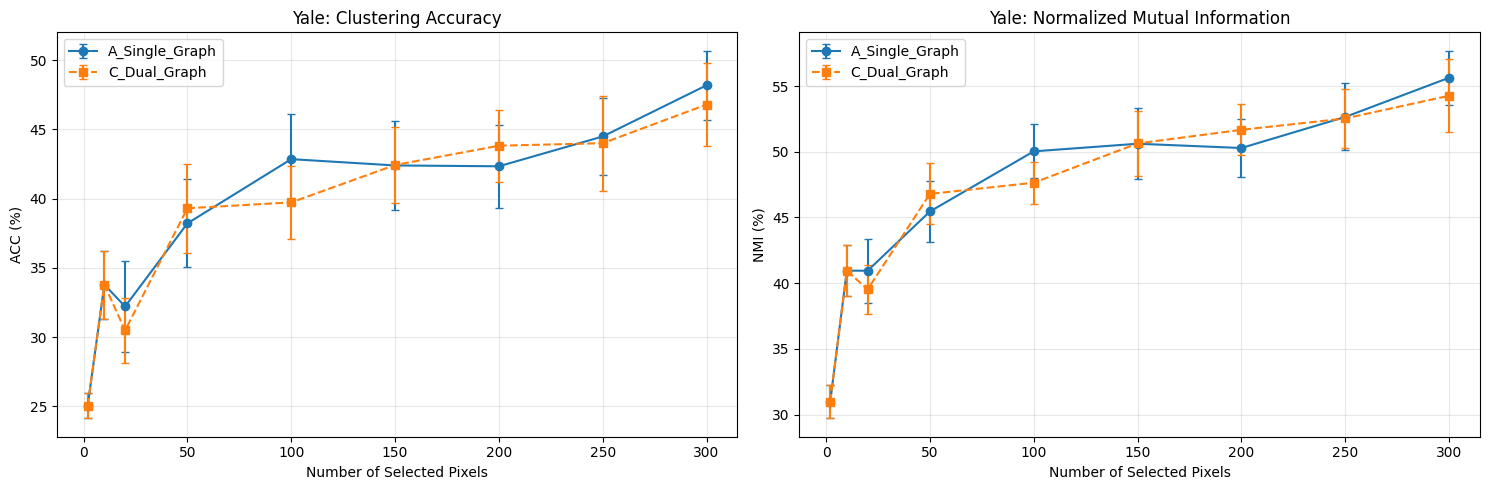

Yale comparison plot created successfully.


In [6]:

import pandas as pd
import matplotlib.pyplot as plt

comparison_rows = []

for r in r_subsets:
    a = results_comb_a_yale[r]
    c = results_comb_c_yale[r]

    comparison_rows.append({
        "Dataset": "Yale",
        "Combination": "A_Single_Graph",
        "Features": r,
        "ACC_mean": a["ACC_mean"],
        "ACC_std": a["ACC_std"],
        "NMI_mean": a["NMI_mean"],
        "NMI_std": a["NMI_std"]
    })

    comparison_rows.append({
        "Dataset": "Yale",
        "Combination": "C_Dual_Graph",
        "Features": r,
        "ACC_mean": c["ACC_mean"],
        "ACC_std": c["ACC_std"],
        "NMI_mean": c["NMI_mean"],
        "NMI_std": c["NMI_std"]
    })

yale_df = pd.DataFrame(comparison_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_styles = {
    "A_Single_Graph": ("o", "-"),
    "C_Dual_Graph": ("s", "--")
}

for combination, (marker, linestyle) in plot_styles.items():
    subset = yale_df[yale_df["Combination"] == combination]

    axes[0].errorbar(
        subset["Features"], subset["ACC_mean"],
        yerr=subset["ACC_std"],
        marker=marker, linestyle=linestyle,
        capsize=3, label=combination
    )

    axes[1].errorbar(
        subset["Features"], subset["NMI_mean"],
        yerr=subset["NMI_std"],
        marker=marker, linestyle=linestyle,
        capsize=3, label=combination
    )

axes[0].set_title("Yale: Clustering Accuracy")
axes[0].set_xlabel("Number of Selected Pixels")
axes[0].set_ylabel("ACC (%)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title("Yale: Normalized Mutual Information")
axes[1].set_xlabel("Number of Selected Pixels")
axes[1].set_ylabel("NMI (%)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.tight_layout()

plt.show()

print("Yale comparison plot created successfully.")


In [7]:

# SAVE YALE COMPARISON PLOT

import os

os.makedirs("../reports/figures", exist_ok=True)

plot_path = "../reports/figures/Yale_All_Combinations_Comparison.png"

fig.savefig(plot_path, dpi=300, bbox_inches="tight")

print(f"Plot saved successfully: {plot_path}")


Plot saved successfully: ../reports/figures/Yale_All_Combinations_Comparison.png


### Save the CSV file

In [9]:

# SAVE YALE RESULTS IN THE EXISTING CSV SCHEMA

import os
import pandas as pd

csv_path = "../reports/results/accuracy_nmi.csv"

# Ensure the experiment results are available
assert "results_comb_a_yale" in globals(), "Run Combination A first."
assert "results_comb_c_yale" in globals(), "Run Combination C first."

# Read the existing CSV
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Central CSV not found: {csv_path}")

central_df = pd.read_csv(csv_path)

if "Dataset" not in central_df.columns:
    raise ValueError("The central CSV has no Dataset column.")

print("Original CSV shape:", central_df.shape)

# Remove ONLY previous Yale rows.
# Every other dataset remains unchanged.
non_yale_df = central_df[
    central_df["Dataset"].astype(str).str.strip().str.lower() != "yale"
].copy()

# Build Yale records using the existing 24-column schema
yale_rows = []

experiment_settings = {
    "Num_Samples": 165,
    "Num_Original_Features": 1024,
    "Num_Classes": 15,
    "Hidden_Dimension": 200,
    "Alpha": 1e-2,
    "Beta": 1e-4,
    "Gamma": 1e-3,
    "Omega": 0.01,
    "Learning_Rate": 5e-4,
    "Epochs": 500,
    "KNN": 5,
    "Repetitions": 20,
    "Lam": 1e-4,
    "Eta": 0.0,
}

combinations = [
    ("A_Single_Graph", results_comb_a_yale, 0.0),
    ("C_Dual_Graph", results_comb_c_yale, 0.01),
]

for method, result_dict, eta_value in combinations:
    for r, metrics in result_dict.items():

        row = {col: pd.NA for col in central_df.columns}

        # Use the existing CSV's column names
        row["Method"] = method
        row["Dataset"] = "Yale"
        row["Num_Features"] = r
        row["Num_Selected_Features"] = r
        row["ACC_Mean"] = metrics["ACC_mean"]
        row["ACC_STD"] = metrics["ACC_std"]
        row["NMI_Mean"] = metrics["NMI_mean"]
        row["NMI_STD"] = metrics["NMI_std"]

        # Fill available experiment metadata
        for col, value in experiment_settings.items():
            if col in row:
                row[col] = value

        # Combination C uses feature-graph regularization;
        # Combination A does not.
        if "Eta" in row:
            row["Eta"] = eta_value

        # These columns are for single-value metrics in the schema.
        # Keep them empty because this experiment reports mean ± std.
        for col in ["ACC", "NMI"]:
            if col in row:
                row[col] = pd.NA

        yale_rows.append(row)

yale_export_df = pd.DataFrame(yale_rows, columns=central_df.columns)

# Append the newly generated Yale rows to all non-Yale records
updated_df = pd.concat(
    [non_yale_df, yale_export_df],
    ignore_index=True
)

# Overwrite the existing CSV
updated_df.to_csv(csv_path, index=False)

# Verify the result
check_df = pd.read_csv(csv_path)
yale_check = check_df[
    check_df["Dataset"].astype(str).str.strip().str.lower() == "yale"
]

print("\nCSV successfully updated:", csv_path)
print("Final CSV shape:", check_df.shape)
print("Yale rows:", len(yale_check))
print("Yale methods:", yale_check["Method"].unique().tolist())
print("Yale feature counts:", sorted(yale_check["Num_Features"].dropna().unique()))

print("\nYale results:")
print(
    yale_check[
        ["Method", "Dataset", "Num_Features",
         "ACC_Mean", "ACC_STD", "NMI_Mean", "NMI_STD",
         "Num_Samples", "Num_Original_Features", "Num_Classes",
         "Hidden_Dimension", "Eta"]
    ].to_string(index=False)
)

print("\nDataset counts:")
print(check_df["Dataset"].value_counts(dropna=False))


Original CSV shape: (101, 30)

CSV successfully updated: ../reports/results/accuracy_nmi.csv
Final CSV shape: (101, 30)
Yale rows: 18
Yale methods: ['A_Single_Graph', 'C_Dual_Graph']
Yale feature counts: [np.float64(2.0), np.float64(10.0), np.float64(20.0), np.float64(50.0), np.float64(100.0), np.float64(150.0), np.float64(200.0), np.float64(250.0), np.float64(300.0)]

Yale results:
        Method Dataset  Num_Features  ACC_Mean  ACC_STD  NMI_Mean  NMI_STD  Num_Samples  Num_Original_Features  Num_Classes  Hidden_Dimension  Eta
A_Single_Graph    Yale           2.0 25.060606 0.924615 30.990551 1.270196        165.0                 1024.0         15.0             200.0 0.00
A_Single_Graph    Yale          10.0 33.787879 2.445926 40.958746 1.930172        165.0                 1024.0         15.0             200.0 0.00
A_Single_Graph    Yale          20.0 32.212121 3.287704 40.949116 2.449689        165.0                 1024.0         15.0             200.0 0.00
A_Single_Graph    Yale    

C:\Users\msheb\AppData\Local\Temp\ipykernel_20600\636219781.py:90: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated_df = pd.concat(


### Yale Dataset Benchmark: Final Summary

| Model Variant | Parameters | ACC (%) | NMI (%) |
|---|---|---:|---:|
| Original Combination A | \(m=200,\ \alpha=0.01\) | \(48.18 \pm 2.50\) | \(55.63 \pm 2.06\) |
| Fine-Tuned Combination C | \(m=100,\ \alpha=0.001,\ \eta=0.005\) | \(47.12 \pm 3.67\) | \(54.65 \pm 2.94\) |
| Updated Combination A | \(m=100,\ \alpha=0.001\) | \(47.12 \pm 3.67\) | \(54.65 \pm 2.94\) |
| Original Paper Benchmark | — | \(49.00 \pm 5.00\) | \(53.00 \pm 5.00\) |

**Key Findings:**
- Original Combination A achieved **55.63% NMI**, higher than the paper's reported 53%.
- Its ACC was **48.18%**, slightly below the reported 49%.
- Fine-tuning did not improve performance; ACC ranged from 47.12% to 48.18% across the tested configurations.
- Further experiments are needed to confirm these results and identify effective parameter settings.